In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import scipy as sp
from tabulate import tabulate
import random
import tensorflow as tf

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [16]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jainilcoder/online-payment-fraud-detection")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'online-payment-fraud-detection' dataset.
Path to dataset files: /kaggle/input/online-payment-fraud-detection


In [17]:
df = pd.read_csv(os.path.join(path, 'onlinefraud.csv'))

df.drop('isFlaggedFraud', axis=1, inplace=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 10 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
dtypes: float64(5), int64(2), object(3)
memory usage: 485.4+ MB


In [18]:
df.sample(5)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
3737323,278,CASH_IN,330218.42,C632336343,20866.00,351084.42,C834976624,452419.57,122201.15,0
264914,15,PAYMENT,11647.08,C1264712553,30370.00,18722.92,M215391829,0.00,0.00,0
85647,10,CASH_IN,152264.21,C1746846248,106589.00,258853.21,C1607284477,201303.01,49038.80,0
5899326,403,TRANSFER,1551760.63,C333676753,0.00,0.00,C1564353608,3198359.45,4750120.08,0
2544263,206,CASH_IN,78172.30,C813403091,2921331.58,2999503.88,C1091768874,415821.90,337649.60,0


In [19]:
df.isnull()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
6362615,False,False,False,False,False,False,False,False,False,False
6362616,False,False,False,False,False,False,False,False,False,False
6362617,False,False,False,False,False,False,False,False,False,False
6362618,False,False,False,False,False,False,False,False,False,False


In [20]:
fraud_min_max = [
    ['amount', df.amount.min(), df.amount.max()],
    ['oldbalanceOrg', df.oldbalanceOrg.min(), df.oldbalanceOrg.max()],
    ['newbalanceOrig', df.newbalanceOrig.min(), df.newbalanceOrig.max()],
    ['oldbalanceDest', df.oldbalanceDest.min(), df.oldbalanceDest.max()],
    ['isFraud', df.isFraud.min(), df.isFraud.max()]
]

print(
    tabulate(
        fraud_min_max,
        headers=['columns', 'min value', 'max value'],
        showindex=True,
        tablefmt='github',
        numalign='right'
    )
)

|    | columns        |   min value |   max value |
|----|----------------|-------------|-------------|
|  0 | amount         |           0 | 9.24455e+07 |
|  1 | oldbalanceOrg  |           0 |  5.9585e+07 |
|  2 | newbalanceOrig |           0 |  4.9585e+07 |
|  3 | oldbalanceDest |           0 | 3.56016e+08 |
|  4 | isFraud        |           0 |           1 |


Text(0.5, 1.0, 'Correlation')

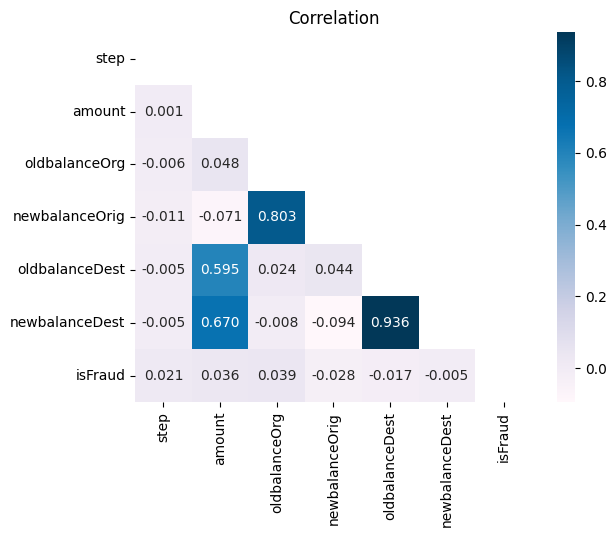

In [21]:
df_numeric = df.drop(['type', 'nameOrig', 'nameDest'], axis=1)
corr_matrix = df_numeric.corr('spearman')
sns.heatmap(corr_matrix, cbar=True, annot=True, mask = np.triu(np.ones_like(corr_matrix, dtype = bool)), fmt='.3f', cmap='PuBu')
plt.title('Correlation')

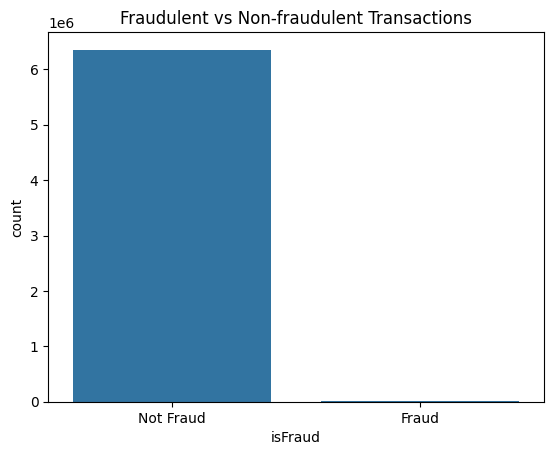

In [22]:
sns.countplot(data=df, x='isFraud')
plt.title('Fraudulent vs Non-fraudulent Transactions')
plt.xticks([0,1], ['Not Fraud','Fraud'])
plt.show()

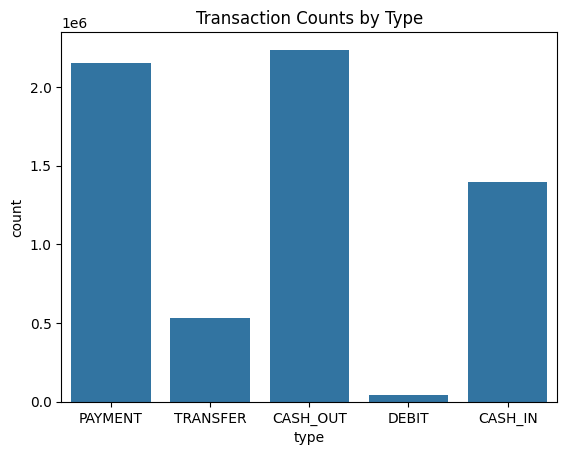

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='type')
plt.title('Transaction Counts by Type')
plt.show()


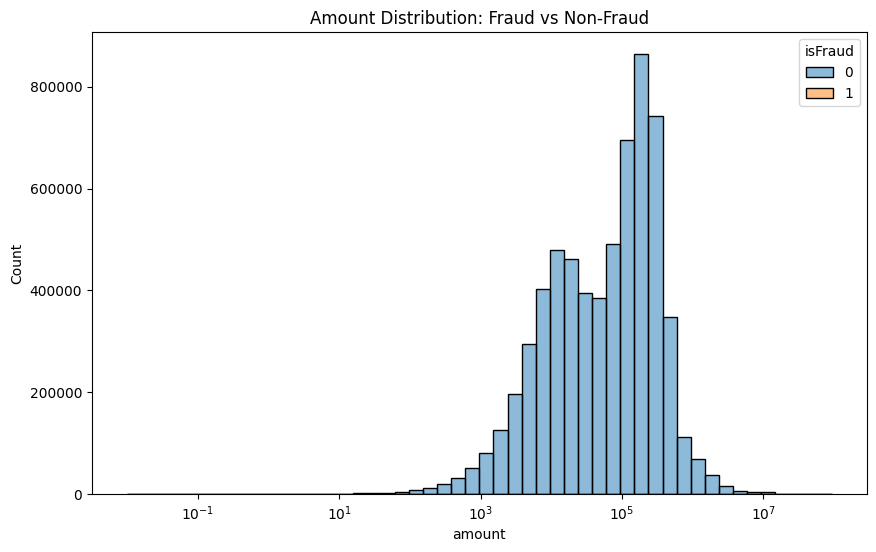

In [24]:
plt.figure(figsize=(10,6))
sns.histplot(data=df, x='amount', hue='isFraud', bins=50, log_scale=True)
plt.title('Amount Distribution: Fraud vs Non-Fraud')
plt.show()


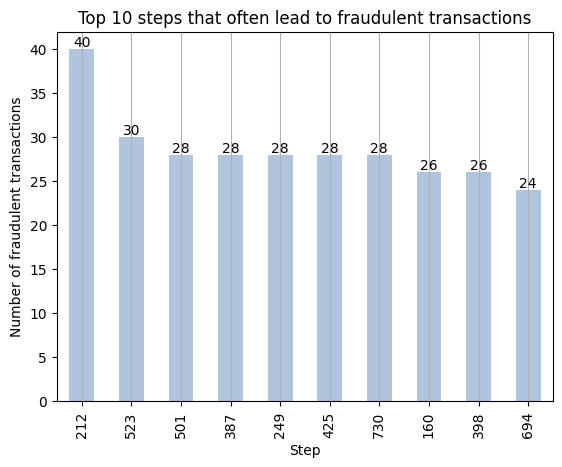

In [29]:
df1 = df[df['isFraud']==1]
df2 = df1['step'].value_counts().head(10)
ax = df2.plot(kind='bar', color='lightsteelblue')
for container in ax.containers:
    ax.bar_label(container)
plt.title('Top 10 steps that often lead to fraudulent transactions')
plt.ylabel('Number of fraudulent transactions')
plt.xlabel('Step')
plt.grid(axis='x')

del ax, df2

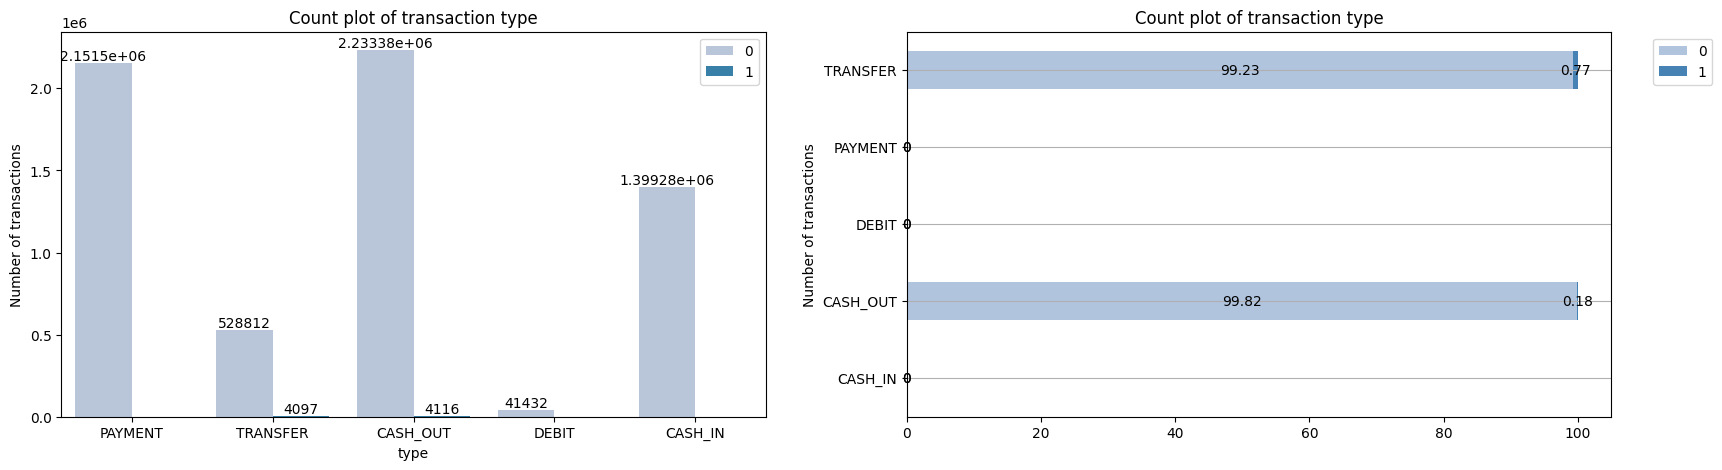

In [28]:
fig, ax = plt.subplots(1,2,figsize=(20,5))

sns.countplot(x='type', data=df, hue='isFraud', palette='PuBu', ax=ax[0])
for container in ax[0].containers:
    ax[0].bar_label(container)
ax[0].set_title('Count plot of transaction type')
ax[0].legend(loc='best')
ax[0].set_ylabel('Number of transactions')

df2 = df.groupby(['type', 'isFraud']).size().unstack()
df2.apply(lambda x : round(x/sum(x)*100, 2), axis=1).plot(kind='barh', stacked=True, color=['lightsteelblue', 'steelblue'], ax=ax[1])
for container in ax[1].containers:
    ax[1].bar_label(container, label_type='center')
ax[1].set_title('Count plot of transaction type')
ax[1].legend(bbox_to_anchor=(1.05,1), loc='upper left')
ax[1].set_ylabel('Number of transactions')
ax[1].grid(axis='y')

Text(0.5, 1.0, 'Correlation')

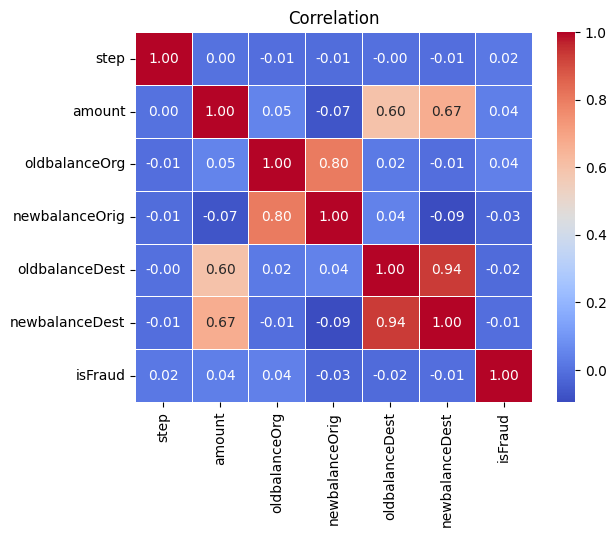

In [25]:

corr_matrix = df_numeric.corr('spearman')
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation')

              precision    recall  f1-score   support

           0       1.00      0.98      0.99   1270881
           1       0.06      1.00      0.11      1643

    accuracy                           0.98   1272524
   macro avg       0.53      0.99      0.55   1272524
weighted avg       1.00      0.98      0.99   1272524



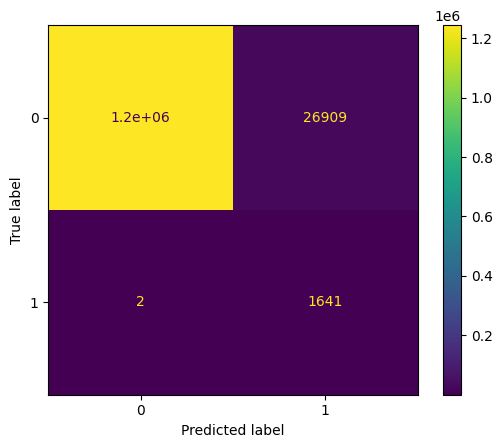

In [26]:
import numpy as np
import pandas as pd
import random
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Set seeds
seed = 42
np.random.seed(seed)
random.seed(seed)
tf.random.set_seed(seed)

# Step 1: Data Cleaning
df_clean = df.copy()
# Drop columns not needed
df_clean.drop(['nameOrig', 'newbalanceOrig', 'nameDest', 'newbalanceDest'], axis=1, inplace=True)

# Step 2: Separate features and target
X = df_clean.drop('isFraud', axis=1)
y = df_clean['isFraud']

# Step 3: Identify categorical and numerical columns
categorical_features = ['type']
numerical_features = X.select_dtypes(include=np.number).columns.tolist()
if 'step' in numerical_features:
    numerical_features.remove('step')

# Step 4: Preprocessing pipelines
numerical_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Step 5: Apply preprocessing
X_processed = preprocessor.fit_transform(X)

# Optional: convert to DataFrame
cat_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
all_feature_names = numerical_features + list(cat_feature_names)
X_processed = pd.DataFrame(X_processed, columns=all_feature_names)

# Step 6: Split into train and test
X_train, X_test, y_train, y_test = train_test_split(
    X_processed, y, test_size=0.2, stratify=y, random_state=seed
)

# Step 7: Handle class imbalance
X_train, y_train = RandomUnderSampler(sampling_strategy='majority', random_state=seed).fit_resample(X_train, y_train)

# Step 8: Train the model
clf = RandomForestClassifier(random_state=seed)
clf.fit(X_train, y_train)

# Step 9: Evaluate
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test)


Random Forest Classifier:
               precision    recall  f1-score   support

Non-Fraud [0]       0.98      1.00      0.99   1243974
    Fraud [1]       1.00      0.06      0.11     28550

     accuracy                           0.98   1272524
    macro avg       0.99      0.53      0.55   1272524
 weighted avg       0.98      0.98      0.97   1272524
 



Text(0.5, 0, 'False Positive Rate')

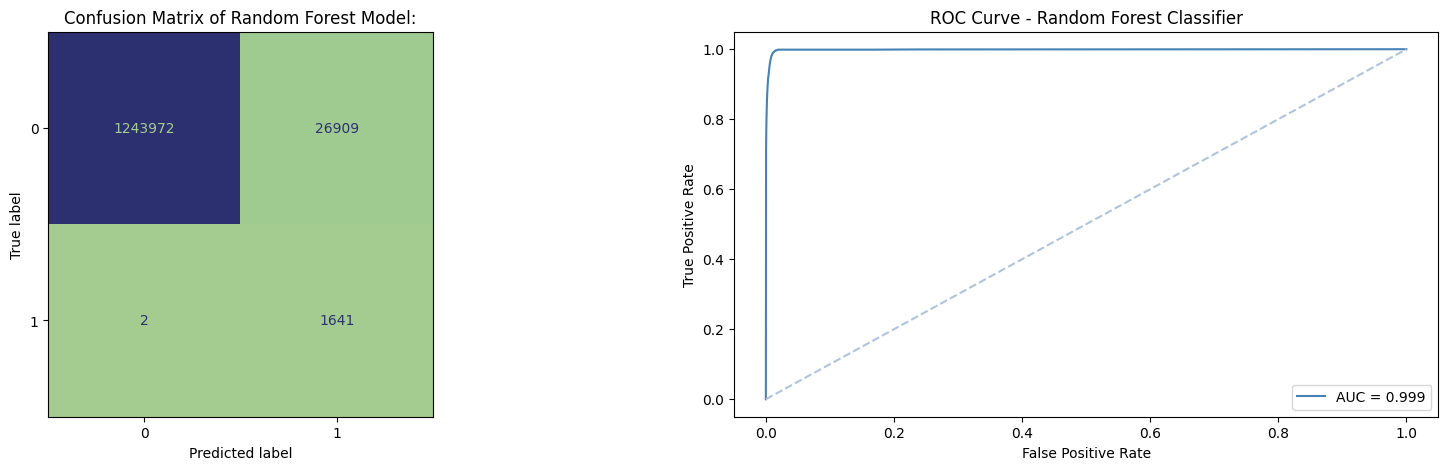

In [31]:
from sklearn.metrics import classification_report, roc_curve, auc, ConfusionMatrixDisplay
model = RandomForestClassifier(class_weight='balanced', random_state=seed)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_pred_score = model.predict_proba(X_test)[:,1]
print('Random Forest Classifier:')
print(classification_report(y_pred, y_test, labels=[0,1], target_names=['Non-Fraud [0]', 'Fraud [1]']), '\n')



fig, ax = plt.subplots(1, 2, figsize=(20,5))
ax[0].set_title('Confusion Matrix of Random Forest Model:')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, colorbar=False, values_format='', cmap='crest', ax=ax[0])
ax[0].grid(False)



fpr, tpr, thresholds = roc_curve(y_test, y_pred_score)
roc_auc = auc(fpr, tpr)
ax[1].set_title('ROC Curve - Random Forest Classifier')
ax[1].plot(fpr, tpr, label = 'AUC = %0.3f' % roc_auc, c='steelblue')
ax[1].plot([0,1],[0,1],'--', c='lightsteelblue')
ax[1].legend(loc='lower right')
ax[1].set_ylabel('True Positive Rate')
ax[1].set_xlabel('False Positive Rate')

In [32]:

new_data = pd.DataFrame([{
    'step': 10,
    'type': 'CASH_OUT',
    'amount': 50000.0,
    'oldbalanceOrg': 100000.0,
    'oldbalanceDest': 20000.0
}])


new_processed = preprocessor.transform(new_data)

# Predict
prediction = clf.predict(new_processed)
probability = clf.predict_proba(new_processed)

print("Predicted Class:", prediction[0])  # 0 = Not Fraud, 1 = Fraud
print("Fraud Probability:", probability[0][1])


Predicted Class: 0
Fraud Probability: 0.35


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
